# Tiamat — Classificação de candidatos a exoplanetas

**Autor:** Gustavo Placido  
**Instituição:** Ilum Escola de Ciência — CNPEM  
**Fonte:** NASA Exoplanet Archive, Kepler Q1–Q17 DR25  
**Escopo:** requisitos obrigatórios; três algoritmos, baseline e 100 configurações por algoritmo.

**Pergunta científica:** com que desempenho características do trânsito, da detecção e da estrela permitem distinguir candidatos a planeta de falsos positivos no catálogo Kepler DR25?

Quando um objeto passa à frente de uma estrela, o brilho observado pode diminuir: esse é o método de trânsito. Estrelas binárias, variabilidade e artefatos instrumentais também podem produzir sinais semelhantes. A tarefa aqui é reproduzir a classificação de triagem do catálogo, usando dados reais já resumidos em uma tabela [1–3]. **Candidato não significa planeta confirmado.** Não se trata de descobrir novos planetas nem de estimar sua frequência no Universo.

Leia e execute as células de cima para baixo. Os dados e resultados acompanham o pacote; se o CSV estiver ausente, a célula de aquisição baixa o mesmo recorte. A otimização é executada novamente em cada execução completa.

## 1. Preparação

Execute a instalação abaixo apenas se necessário. O experimento utiliza uma separação fixa treino/validação/teste; não utiliza validação cruzada, PCA, seleção automática de atributos, SHAP, permutation importance ou HPC.

In [1]:
# Se faltar alguma biblioteca, descomente e execute a linha abaixo.
# %pip install -r requirements.txt

In [2]:
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import optuna
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 42
N_TRIALS = 100  # Não diminuir: exigência do Tiamat para cada algoritmo.
N_JOBS = 2     # Paralelismo local; não é execução no HPC.
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

BASE = Path.cwd()
DADOS = BASE / 'dados'
RESULTADOS = BASE / 'resultados'
DADOS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
CORES = {0: '#b85b36', 1: '#177e89'}
NOMES_CLASSES = ['Falso positivo', 'Candidato']

versoes = {'python': platform.python_version(), 'numpy': np.__version__,
           'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
           'optuna': optuna.__version__}
display(pd.Series(versoes, name='Versão'))

python          3.12.14
numpy             2.3.5
pandas            2.2.3
scikit-learn      1.8.0
optuna            4.5.0
Name: Versão, dtype: object

## 2. Aquisição e origem dos dados

Usamos a tabela `q1_q17_dr25_koi`, uma entrega específica do catálogo. A tabela cumulativa mistura entregas e não é necessária neste estudo [2]. O filtro `koi_count = 1` reduz a repetição de estrelas; a unicidade de `kepid` será verificada explicitamente, sem assumir que o filtro basta.

Os identificadores e a contagem são conservados apenas para auditoria. Não entram nos modelos. Coordenadas, comentários, `koi_disposition`, `koi_score` e flags finais de falso positivo não são baixados como entradas. As estatísticas de detecção permitidas são medições anteriores à decisão final, mas compartilham a mesma cadeia de processamento do rótulo: a avaliação mede concordância com esse catálogo.

O atributo `koi_bin_oedp_sig`, citado na proposta inicial, foi omitido antes da modelagem por apresentar valores negativos e interpretação insuficientemente clara para este escopo. Permanecem **25 atributos físicos/observacionais**. Essa decisão fixa de qualidade dos dados não é uma busca de atributos pelo Optuna.

In [3]:
ATRIBUTOS = ['koi_gmag', 'koi_rmag', 'koi_jmag', 'koi_hmag', 'koi_kmag', 'koi_kepmag', 'koi_num_transits', 'koi_max_sngle_ev', 'koi_max_mult_ev', 'koi_model_snr', 'koi_prad', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_period', 'koi_ror', 'koi_dor', 'koi_incl', 'koi_teq', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_smass', 'koi_insol', 'koi_srho']
ALVO = 'koi_pdisposition'
IDENTIFICADORES = ['kepid', 'kepoi_name', 'koi_count']
COLUNAS = IDENTIFICADORES + [ALVO] + ATRIBUTOS

CONSULTA = ('SELECT ' + ','.join(COLUNAS)
            + ' FROM q1_q17_dr25_koi WHERE koi_count = 1 ORDER BY kepid, kepoi_name')
URL = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync?' + urlencode(
    {'query': CONSULTA, 'format': 'csv'})
ARQUIVO = DADOS / 'kepler_dr25_original.csv'

if not ARQUIVO.exists():
    with urlopen(URL, timeout=120) as resposta:
        conteudo = resposta.read()
    ARQUIVO.write_bytes(conteudo)
    origem = {'source': 'NASA Exoplanet Archive', 'table': 'q1_q17_dr25_koi',
              'query': CONSULTA, 'url': URL, 'features': ATRIBUTOS,
              'download_utc': datetime.now(timezone.utc).isoformat(),
              'sha256': hashlib.sha256(conteudo).hexdigest()}
    (DADOS / 'proveniencia.json').write_text(
        json.dumps(origem, ensure_ascii=False, indent=2), encoding='utf-8')
    (DADOS / 'consulta.sql').write_text(CONSULTA + '\n', encoding='utf-8')

bruto = pd.read_csv(ARQUIVO)
assert set(COLUNAS).issubset(bruto.columns)
assert bruto['kepid'].is_unique and bruto['kepoi_name'].is_unique
assert bruto['koi_count'].eq(1).all()
origem = json.loads((DADOS / 'proveniencia.json').read_text(encoding='utf-8'))
assert hashlib.sha256(ARQUIVO.read_bytes()).hexdigest() == origem['sha256']
print('Registros originais:', len(bruto))
print('Estrelas distintas:', bruto['kepid'].nunique())
print('Atributos usados:', len(ATRIBUTOS))
print('SHA-256 da cópia:', origem['sha256'])
display(bruto[COLUNAS].head())

Registros originais: 6148
Estrelas distintas: 6148
Atributos usados: 25
SHA-256 da cópia: 716ccf1ed71eac314d983936a4c34e9339c57e150a036ed4437e60beb02c6562


,kepid,kepoi_name,koi_count,koi_pdisposition,koi_gmag,koi_rmag,koi_jmag,koi_hmag,koi_kmag,koi_kepmag,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev,koi_model_snr,koi_prad,koi_impact,koi_duration,koi_depth,koi_period,koi_ror,koi_dor,koi_incl,koi_teq,koi_steff,koi_slogg,koi_srad,koi_smass,koi_insol,koi_srho
0,757450,K00889.01,1,CANDIDATE,15.998,15.207,13.665,13.262,13.118,15.264,153,61.291126,474.020780,388.2,10.51,0.069,2.07004,16053.4,8.884923,0.114124,36.46600,89.89,770.0,5332.0,4.500,0.843,0.821,83.21,11.62061
1,892772,K01009.01,1,FALSE POSITIVE,15.958,15.131,13.546,12.987,12.872,15.162,225,3.647930,15.175163,17.1,1.17,0.161,3.65900,254.0,5.092465,0.014236,10.67000,89.14,844.0,5037.0,4.547,0.751,0.727,119.70,0.88510
2,1025986,K07621.01,1,FALSE POSITIVE,10.574,10.097,8.981,8.718,8.626,10.150,4,5.909186,8.011753,7.5,1.86,0.595,3.37000,228.9,275.073650,0.014379,512.00000,89.93,303.0,5604.0,4.226,1.187,0.864,2.00,33.55994
3,1026032,K06252.01,1,FALSE POSITIVE,15.251,14.777,13.609,13.298,13.277,14.813,164,452.525570,3704.503400,1797.4,36.62,1.061,4.73492,76412.9,8.460439,0.477640,14.08662,85.68,804.0,5951.0,4.638,0.702,0.796,98.60,0.73874
4,1026957,K00958.01,1,CANDIDATE,13.299,12.520,10.982,10.475,10.410,12.559,62,19.203890,96.205444,60.0,2.53,0.123,1.24300,1300.7,21.761298,0.032165,137.07000,89.95,486.0,4859.0,4.612,0.720,0.781,13.18,102.86534


## 3. Dicionário e limpeza

As unidades e interpretações seguem a documentação do arquivo [1]. Alguns parâmetros de planeta são ajustes sob a hipótese de trânsito: em falsos positivos, valores extremos não devem ser interpretados como planetas físicos extremos. Não excluímos outliers usando a classe.

Mantemos apenas os dois rótulos de interesse, removemos duplicatas exatas e eliminamos linhas incompletas nos atributos predefinidos. A remoção de casos completos simplifica o primeiro estudo, mas pode introduzir viés de seleção; quantificamos a perda por classe. Não há imputação nem transformação aprendida nesta etapa.

In [4]:
dicionario = pd.DataFrame([('koi_gmag', 'Magnitude na banda g', 'mag', 'Fotometria'), ('koi_rmag', 'Magnitude na banda r', 'mag', 'Fotometria'), ('koi_jmag', 'Magnitude na banda J', 'mag', 'Fotometria'), ('koi_hmag', 'Magnitude na banda H', 'mag', 'Fotometria'), ('koi_kmag', 'Magnitude na banda K', 'mag', 'Fotometria'), ('koi_kepmag', 'Magnitude na banda Kepler', 'mag', 'Fotometria'), ('koi_num_transits', 'Número de trânsitos observados', 'contagem', 'Detecção'), ('koi_max_sngle_ev', 'Máximo da estatística de evento único (SES)', 'estatística normalizada', 'Detecção'), ('koi_max_mult_ev', 'Máximo da estatística de eventos múltiplos (MES)', 'estatística normalizada', 'Detecção'), ('koi_model_snr', 'Razão sinal/ruído do trânsito ajustado', 'adimensional', 'Detecção'), ('koi_prad', 'Raio do objeto ajustado sob hipótese planetária', 'raios terrestres', 'Trânsito'), ('koi_impact', 'Distância projetada no trânsito / raio estelar', 'adimensional', 'Trânsito'), ('koi_duration', 'Duração do trânsito', 'horas', 'Trânsito'), ('koi_depth', 'Profundidade do trânsito', 'ppm', 'Trânsito'), ('koi_period', 'Período orbital ajustado', 'dias', 'Trânsito'), ('koi_ror', 'Razão dos raios objeto/estrela', 'adimensional', 'Trânsito'), ('koi_dor', 'Semieixo orbital / raio estelar', 'adimensional', 'Trânsito'), ('koi_incl', 'Inclinação orbital ajustada', 'graus', 'Trânsito'), ('koi_teq', 'Temperatura de equilíbrio estimada', 'K', 'Estimativa física'), ('koi_steff', 'Temperatura efetiva da estrela', 'K', 'Estrela'), ('koi_slogg', 'Log10 da gravidade superficial estelar em cgs', 'log10(cm/s²)', 'Estrela'), ('koi_srad', 'Raio da estrela', 'raios solares', 'Estrela'), ('koi_smass', 'Massa da estrela', 'massas solares', 'Estrela'), ('koi_insol', 'Fluxo incidente em unidades terrestres', 'fluxo terrestre', 'Estimativa física'), ('koi_srho', 'Densidade estelar ajustada pelo trânsito', 'g/cm³', 'Trânsito')],
    columns=['Atributo', 'Descrição', 'Unidade', 'Grupo'])
display(dicionario)
dicionario.to_csv(DADOS / 'dicionario_atributos.csv', index=False)

validos = bruto.loc[bruto[ALVO].isin(['FALSE POSITIVE', 'CANDIDATE']), COLUNAS].copy()
n_duplicatas = int(validos.duplicated().sum())
validos = validos.drop_duplicates()
ausentes = validos[ATRIBUTOS].isna().sum().sort_values(ascending=False)
display(ausentes.loc[ausentes.gt(0)].rename('Ausentes'))
print('Duplicatas exatas removidas:', n_duplicatas)

df = validos.dropna(subset=ATRIBUTOS).copy().reset_index(drop=True)
auditoria = pd.concat([validos[ALVO].value_counts().rename('Antes'),
                      df[ALVO].value_counts().rename('Depois')], axis=1)
auditoria['Removidos'] = auditoria['Antes'] - auditoria['Depois']
auditoria['Perda (%)'] = 100 * auditoria['Removidos'] / auditoria['Antes']
display(auditoria.round(2))

assert len(df) >= 300 and len(ATRIBUTOS) >= 10
assert df['kepid'].is_unique and df['kepoi_name'].is_unique
assert not df[ATRIBUTOS].isna().any().any()
assert np.isfinite(df[ATRIBUTOS].to_numpy()).all()
assert not df.duplicated(subset=ATRIBUTOS).any()

# Candidato = classe positiva 1; falso positivo do catálogo = classe 0.
y = df[ALVO].map({'FALSE POSITIVE': 0, 'CANDIDATE': 1}).astype(int)
X = df[ATRIBUTOS].copy()
print(f'Base final: {len(df)} exemplos, {X.shape[1]} atributos.')
print('Legenda:', {0: 'FALSE POSITIVE', 1: 'CANDIDATE'})
auditoria.to_csv(RESULTADOS / 'auditoria_limpeza.csv')

Duplicatas exatas removidas: 0
Base final: 6041 exemplos, 25 atributos.
Legenda: {0: 'FALSE POSITIVE', 1: 'CANDIDATE'}


,Atributo,Descrição,Unidade,Grupo
0,koi_gmag,Magnitude na banda g,mag,Fotometria
1,koi_rmag,Magnitude na banda r,mag,Fotometria
2,koi_jmag,Magnitude na banda J,mag,Fotometria
3,koi_hmag,Magnitude na banda H,mag,Fotometria
4,koi_kmag,Magnitude na banda K,mag,Fotometria
5,koi_kepmag,Magnitude na banda Kepler,mag,Fotometria
6,koi_num_transits,Número de trânsitos observados,contagem,Detecção
7,koi_max_sngle_ev,Máximo da estatística de evento único (SES),estatística normalizada,Detecção
8,koi_max_mult_ev,Máximo da estatística de eventos múltiplos (MES),estatística normalizada,Detecção
9,koi_model_snr,Razão sinal/ruído do trânsito ajustado,adimensional,Detecção


koi_srad         52
koi_incl         52
koi_teq          52
koi_ror          52
koi_dor          52
koi_depth        52
koi_impact       52
koi_prad         52
koi_model_snr    52
koi_insol        52
koi_smass        52
koi_steff        52
koi_slogg        52
koi_srho         52
koi_gmag         29
koi_hmag         25
koi_jmag         25
koi_kmag         25
koi_rmag          4
koi_kepmag        1
Name: Ausentes, dtype: int64

,Antes,Depois,Removidos,Perda (%)
koi_pdisposition,,,,
FALSE POSITIVE,3795,3696,99,2.61
CANDIDATE,2353,2345,8,0.34


## 4. Separação antes da exploração e do ajuste

Separamos 20% para teste e dividimos os 80% restantes em treino (60% do total) e validação (20%). A estratificação preserva aproximadamente a proporção das classes. Cada estrela aparece em apenas uma parte.

**Treino:** ajusta parâmetros e, na regressão logística, a escala. **Validação:** orienta as 100 tentativas do Optuna e escolhe o algoritmo. **Teste:** é consultado somente depois de todas as escolhas. É uma validação holdout, sem validação cruzada [4].

In [5]:
indices_dev, indices_teste = train_test_split(
    df.index.to_numpy(), test_size=0.20, stratify=y, random_state=SEED)
indices_treino, indices_val = train_test_split(
    indices_dev, test_size=0.25, stratify=y.loc[indices_dev], random_state=SEED)

assert set(indices_treino).isdisjoint(indices_val)
assert set(indices_treino).isdisjoint(indices_teste)
assert set(indices_val).isdisjoint(indices_teste)
assert set(indices_treino) | set(indices_val) | set(indices_teste) == set(df.index)

X_treino, y_treino = X.loc[indices_treino], y.loc[indices_treino]
X_val, y_val = X.loc[indices_val], y.loc[indices_val]
X_teste, y_teste = X.loc[indices_teste], y.loc[indices_teste]

partes = {'Treino': indices_treino, 'Validação': indices_val, 'Teste': indices_teste}
resumo_partes = []
for nome, idx in partes.items():
    resumo_partes.append({'Parte': nome, 'Exemplos': len(idx),
                         'Candidatos': int(y.loc[idx].sum()),
                         'Falsos positivos': int((y.loc[idx] == 0).sum())})
    df.loc[idx, ['kepid', 'kepoi_name']].assign(parte=nome).to_csv(
        RESULTADOS / f'ids_{nome.lower().replace("ç", "c").replace("ã", "a")}.csv', index=False)
display(pd.DataFrame(resumo_partes).set_index('Parte'))

,Exemplos,Candidatos,Falsos positivos
Parte,,,
Treino,3624,1407,2217
Validação,1208,469,739
Teste,1209,469,740


## 5. Análise exploratória — somente treino

Examinamos a proporção das classes, estatísticas descritivas, distribuições de seis atributos e correlações. As escalas logarítmicas dos histogramas servem apenas à visualização; não transformam as entradas do modelo. Correlação não demonstra causalidade nem determina a seleção de atributos neste trabalho.

Pares com maior correlação absoluta (descrição, sem excluir atributos):


,count,mean,std,min,25%,50%,75%,max
koi_gmag,3624.0,14.867,1.486,7.604,13.963,15.104,15.978,20.378
koi_rmag,3624.0,14.266,1.367,7.558,13.445,14.512,15.302,19.273
koi_jmag,3624.0,13.047,1.289,4.097,12.303,13.286,13.987,16.761
koi_hmag,3624.0,12.676,1.263,3.014,11.984,12.897,13.595,16.309
koi_kmag,3624.0,12.599,1.264,2.311,11.910,12.811,13.518,16.975
koi_kepmag,3624.0,14.310,1.368,7.570,13.505,14.563,15.352,19.294
koi_num_transits,3624.0,437.459,586.890,0.000,40.000,168.000,611.250,2664.000
koi_max_sngle_ev,3624.0,239.622,924.929,2.537,3.986,5.682,39.335,22982.162
koi_max_mult_ev,3624.0,1372.119,4604.776,7.106,11.034,20.278,186.820,63391.190
koi_model_snr,3624.0,371.194,971.535,0.800,14.200,29.000,160.300,9054.700


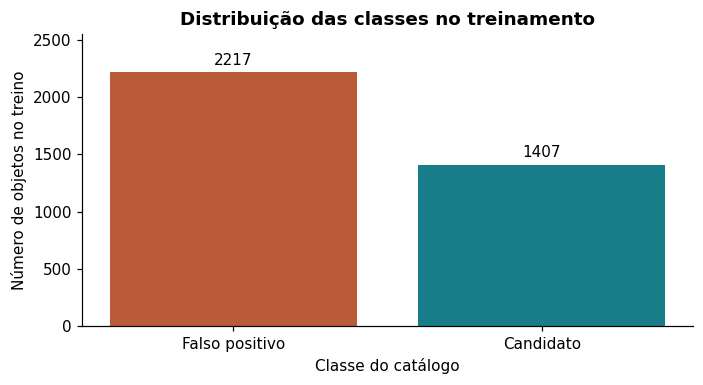

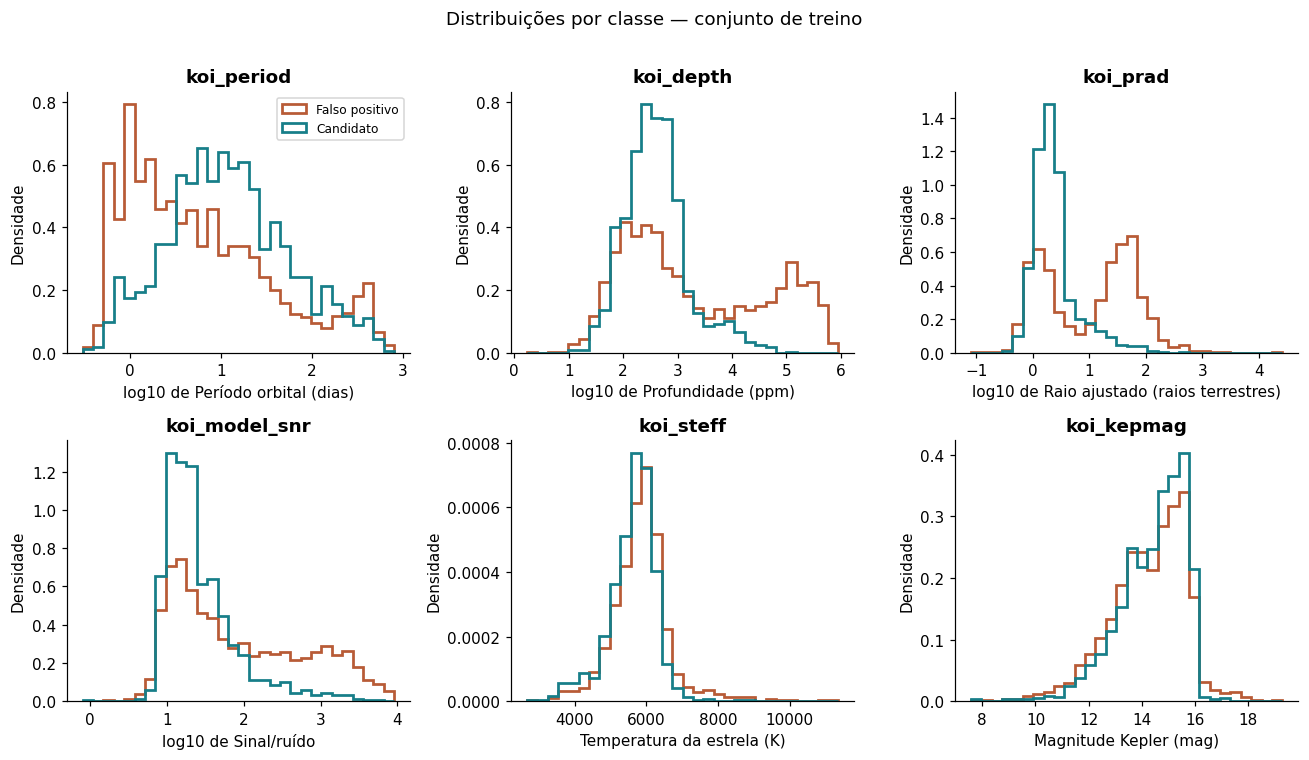

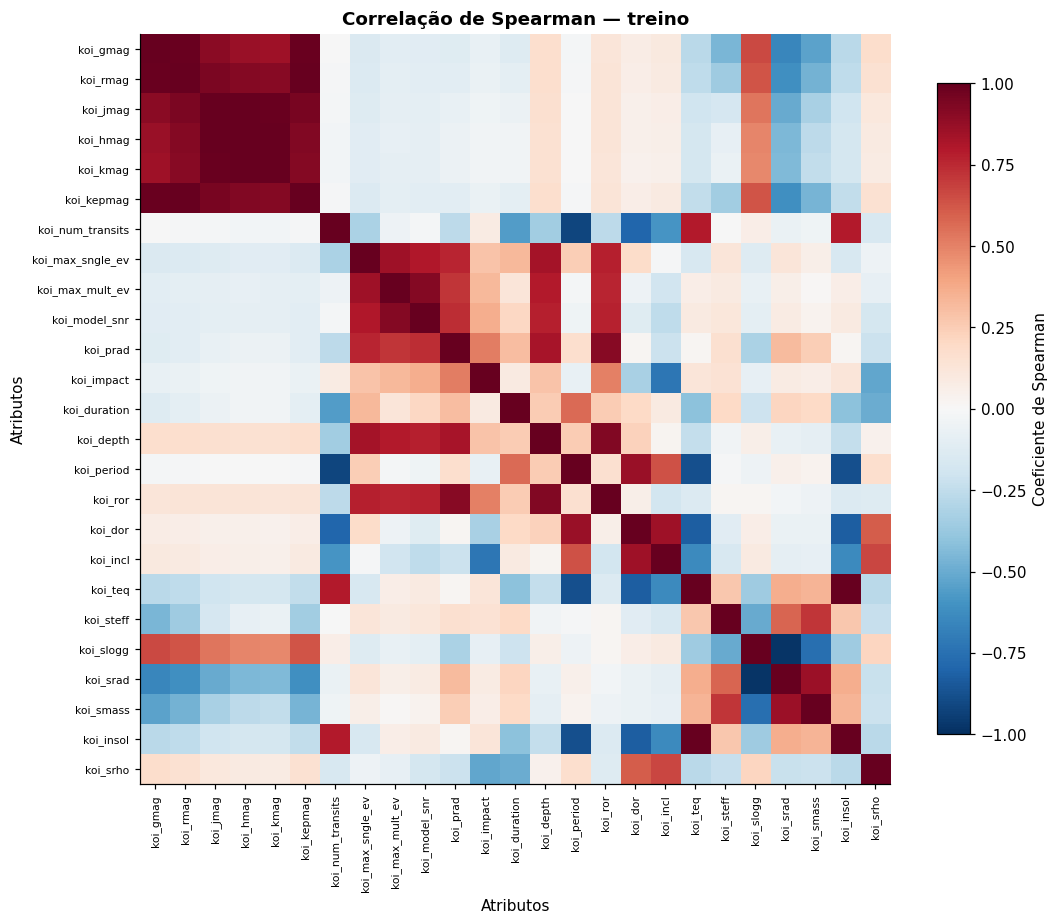

Spearman
koi_teq   koi_insol   0.999999
koi_rmag  koi_kepmag  0.999240
koi_hmag  koi_kmag    0.998198
koi_jmag  koi_hmag    0.992659
          koi_kmag    0.988926
koi_gmag  koi_rmag    0.986971
          koi_kepmag  0.985295
koi_slogg koi_srad   -0.978072

In [6]:
display(X_treino.describe().T.round(3))
contagens = y_treino.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
barras = ax.bar(NOMES_CLASSES, contagens.values, color=[CORES[0], CORES[1]])
ax.bar_label(barras, padding=3)
ax.set(xlabel='Classe do catálogo', ylabel='Número de objetos no treino',
       title='Distribuição das classes no treinamento', ylim=(0, contagens.max() * 1.15))
fig.tight_layout()
fig.savefig(RESULTADOS / '01_classes_treino.png', bbox_inches='tight')
plt.show()

fig, eixos = plt.subplots(2, 3, figsize=(12, 6.8))
variaveis_plot = [('koi_period', 'Período orbital (dias)', True),
                  ('koi_depth', 'Profundidade (ppm)', True),
                  ('koi_prad', 'Raio ajustado (raios terrestres)', True),
                  ('koi_model_snr', 'Sinal/ruído', True),
                  ('koi_steff', 'Temperatura da estrela (K)', False),
                  ('koi_kepmag', 'Magnitude Kepler (mag)', False)]
for ax, (col, rotulo, usar_log) in zip(eixos.flat, variaveis_plot):
    valores = np.log10(X_treino[col]) if usar_log else X_treino[col]
    limites = np.histogram_bin_edges(valores, bins=30)
    for classe in [0, 1]:
        ax.hist(valores.loc[y_treino == classe], bins=limites, density=True,
                histtype='step', linewidth=1.8, color=CORES[classe], label=NOMES_CLASSES[classe])
    ax.set(xlabel=('log10 de ' + rotulo if usar_log else rotulo),
           ylabel='Densidade', title=col)
eixos.flat[0].legend(fontsize=8)
fig.suptitle('Distribuições por classe — conjunto de treino', y=1.01)
fig.tight_layout()
fig.savefig(RESULTADOS / '02_distribuicoes_treino.png', bbox_inches='tight')
plt.show()

correlacoes = X_treino.corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(correlacoes, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(ATRIBUTOS)), ATRIBUTOS, rotation=90, fontsize=7)
ax.set_yticks(range(len(ATRIBUTOS)), ATRIBUTOS, fontsize=7)
ax.set(xlabel='Atributos', ylabel='Atributos', title='Correlação de Spearman — treino')
fig.colorbar(im, ax=ax, label='Coeficiente de Spearman', shrink=0.75)
fig.tight_layout()
fig.savefig(RESULTADOS / '03_correlacoes_treino.png', bbox_inches='tight')
plt.show()

print('Pares com maior correlação absoluta (descrição, sem excluir atributos):')
triangulo = correlacoes.where(np.triu(np.ones(correlacoes.shape), k=1).astype(bool))
pares = triangulo.stack().rename('Spearman').to_frame()
display(pares.loc[pares['Spearman'].abs().sort_values(ascending=False).head(8).index])

**Leitura dos gráficos.** O treino contém mais falsos positivos que candidatos. Período, profundidade, raio ajustado e sinal/ruído abrangem várias ordens de grandeza; distribuições sobrepostas impedem separar todos os casos por um único corte. Magnitudes e propriedades físicas derivadas podem ser redundantes. Os valores muito grandes de raio ajustado em falsos positivos reforçam que um ajuste planetário não comprova a existência de um planeta.

## 6. Critério de avaliação e baseline

A métrica principal, definida antes da otimização, é **F1 macro**: a média dos F1 das duas classes, atribuindo o mesmo peso a cada uma. Para cada classe, $F1=2PR/(P+R)$, onde $P$ é precisão e $R$ é recall. Também relatamos acurácia, balanced accuracy, precisão/recall de candidatos e ROC-AUC.

O baseline `DummyClassifier(strategy="most_frequent")` sempre prevê a classe mais frequente do treino. Ele mostra quanto se obtém sem aprender a relação entre atributos e classe. Não recebe Optuna e não conta como um dos três algoritmos.

Usaremos o limiar padrão 0,5 das probabilidades. Não ajustaremos esse limiar com o teste. Classe positiva = **candidato (1)**. Assim, um falso positivo da classificação é um falso positivo do catálogo classificado como candidato; um falso negativo é um candidato descartado pelo modelo.

In [7]:
def calcular_metricas(modelo, entradas, alvo):
    pred = modelo.predict(entradas)
    prob = modelo.predict_proba(entradas)[:, 1]
    return {'Acurácia': accuracy_score(alvo, pred),
            'Balanced accuracy': balanced_accuracy_score(alvo, pred),
            'Precisão candidato': precision_score(alvo, pred, zero_division=0),
            'Recall candidato': recall_score(alvo, pred, zero_division=0),
            'F1 candidato': f1_score(alvo, pred, zero_division=0),
            'F1 macro': f1_score(alvo, pred, average='macro', zero_division=0),
            'ROC-AUC': roc_auc_score(alvo, prob)}

baseline = DummyClassifier(strategy='most_frequent', random_state=SEED)
baseline.fit(X_treino, y_treino)
baseline_val = calcular_metricas(baseline, X_val, y_val)
display(pd.DataFrame([baseline_val], index=['Baseline — validação']).round(4))

,Acurácia,Balanced accuracy,Precisão candidato,Recall candidato,F1 candidato,F1 macro,ROC-AUC
Baseline — validação,0.6118,0.5,0.0,0.0,0.0,0.3796,0.5


## 7. Três algoritmos e espaços de busca

**Regressão logística:** combina linearmente os atributos para estimar a probabilidade de candidato. `StandardScaler` calcula média e desvio apenas no treino. Mantemos penalização L2 e solver `liblinear`; variamos `C` e o peso das classes. `C` menor significa regularização mais forte [5].

**Random Forest:** combina árvores ajustadas a amostras bootstrap e subconjuntos aleatórios de atributos. Não exige padronização; profundidade, tamanho mínimo das folhas e fracionamento dos atributos controlam a complexidade [6].

**HistGradientBoosting:** constrói árvores sucessivas para reduzir a perda de classificação. Taxa de aprendizado, quantidade de iterações, folhas, profundidade e regularização controlam capacidade e sobreajuste. Desativamos early stopping para que o treino não crie outra divisão interna [7].

| Modelo | Hiperparâmetro | Valores | Justificativa |
|---|---|---|---|
| Logística | `C` | 0,0001 a 1.000, escala log | Explorar sete ordens de grandeza na força de regularização |
| Logística | `class_weight` | `None` ou `balanced` | Verificar o efeito da diferença de frequência das classes |
| Random Forest | `n_estimators` | 100 a 300, passo 50 | Reduzir variabilidade sem custo excessivo |
| Random Forest | `max_depth` | 4 a 24 | Comparar árvores rasas e mais expressivas |
| Random Forest | `min_samples_split` | 2 a 20 | Evitar divisões apoiadas em poucos exemplos |
| Random Forest | `min_samples_leaf` | 1 a 15 | Controlar a suavidade das decisões |
| Random Forest | `max_features` | 0,3 a 1,0 | Variar diversidade/correlação entre árvores |
| Random Forest | `max_samples` | 0,65 a 1,0 | Variar o tamanho das amostras bootstrap |
| Random Forest | `class_weight` | `None` ou `balanced` | Comparar com e sem ponderação das classes |
| HistGradientBoosting | `learning_rate` | 0,02 a 0,2, escala log | Ajustar a intensidade de cada etapa |
| HistGradientBoosting | `max_iter` | 100 a 300, passo 50 | Controlar a quantidade de etapas |
| HistGradientBoosting | `max_leaf_nodes` | 7 a 47 | Controlar a complexidade das árvores |
| HistGradientBoosting | `max_depth` | 3 a 10 | Limitar interações de alta ordem |
| HistGradientBoosting | `min_samples_leaf` | 10 a 60 | Reduzir ajuste a grupos pequenos |
| HistGradientBoosting | `l2_regularization` | 0,0001 a 10, escala log | Penalizar valores extremos nas folhas |

Esses intervalos equilibram capacidade de aprendizado e prazo de execução. São escolhas prévias, não limites definidos olhando o teste. A ponderação de classes não cria amostras; não usamos reamostragem. A interpretação dos hiperparâmetros segue [5–8].

In [8]:
NOMES_MODELOS = ['Regressão logística', 'Random Forest', 'HistGradientBoosting']

def sugerir_parametros(trial, nome):
    if nome == 'Regressão logística':
        return {'C': trial.suggest_float('C', 1e-4, 1e3, log=True),
                'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    if nome == 'Random Forest':
        return {'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
                'max_depth': trial.suggest_int('max_depth', 4, 24),
                'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 15),
                'max_features': trial.suggest_float('max_features', 0.3, 1.0),
                'max_samples': trial.suggest_float('max_samples', 0.65, 1.0),
                'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    return {'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
            'max_iter': trial.suggest_int('max_iter', 100, 300, step=50),
            'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 7, 47),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 60),
            'l2_regularization': trial.suggest_float('l2_regularization', 1e-4, 10.0, log=True)}

def construir_modelo(nome, parametros):
    if nome == 'Regressão logística':
        return Pipeline([('escala', StandardScaler()),
                         ('modelo', LogisticRegression(
                             solver='liblinear', max_iter=5000,
                             random_state=SEED, **parametros))])
    if nome == 'Random Forest':
        return RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS, **parametros)
    return HistGradientBoostingClassifier(
        random_state=SEED, early_stopping=False, **parametros)

## 8. Optuna — 100 configurações completas por algoritmo

Cada tentativa constrói um modelo novo, ajusta somente no treino e devolve o F1 macro da validação. O amostrador TPE começa com 20 tentativas de exploração e usa resultados anteriores para sugerir as seguintes [8]. Não há pruning nem limite de tempo interrompendo tentativas. Conferimos também se as configurações completas são distintas.

As três buscas usam os mesmos conjuntos. O teste não aparece na função objetivo. Os históricos são exportados para CSV, tornando verificáveis as 300 avaliações. O tempo depende do computador; acompanhe as mensagens a cada 20 tentativas.

In [9]:
estudos = {}
linhas_validacao = []
melhores_parametros = {}
inicio_total = time.perf_counter()

for numero, nome in enumerate(NOMES_MODELOS):
    print(f'Iniciando: {nome}', flush=True)
    inicio = time.perf_counter()

    def objetivo(trial):
        parametros = sugerir_parametros(trial, nome)
        modelo = construir_modelo(nome, parametros)
        with threadpool_limits(limits=N_JOBS):
            with warnings.catch_warnings():
                warnings.simplefilter('error', ConvergenceWarning)
                modelo.fit(X_treino, y_treino)
            predicao = modelo.predict(X_val)
        return f1_score(y_val, predicao, average='macro', zero_division=0)

    def progresso(study, trial):
        if (trial.number + 1) % 20 == 0:
            print(f'  {trial.number + 1} tentativas; melhor F1 macro = {study.best_value:.4f}',
                  flush=True)

    estudo = optuna.create_study(direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED + numero, n_startup_trials=20))
    estudo.optimize(objetivo, n_trials=N_TRIALS, n_jobs=1, callbacks=[progresso])
    completas = [t for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE]
    unicas = {json.dumps(t.params, sort_keys=True) for t in completas}
    assert len(completas) >= 100 and len(unicas) >= 100

    estudos[nome] = estudo
    melhores_parametros[nome] = estudo.best_params
    melhor = construir_modelo(nome, estudo.best_params)
    with threadpool_limits(limits=N_JOBS):
        melhor.fit(X_treino, y_treino)
        f1_treino = f1_score(y_treino, melhor.predict(X_treino), average='macro')
    linhas_validacao.append({'Modelo': nome, 'F1 macro treino': f1_treino,
        'F1 macro validação': estudo.best_value, 'Tentativas completas': len(completas),
        'Configurações distintas': len(unicas),
        'Tempo (s)': time.perf_counter() - inicio})
    estudo.trials_dataframe().to_csv(
        RESULTADOS / f'optuna_modelo_{numero + 1}.csv', index=False)
    print('Concluído:', nome, flush=True)

tempo_total = time.perf_counter() - inicio_total
tabela_validacao = pd.DataFrame(linhas_validacao).set_index('Modelo')
display(tabela_validacao.round(4))
display(Markdown('**Melhores hiperparâmetros:**'))
print(json.dumps(melhores_parametros, ensure_ascii=False, indent=2))
tabela_validacao.to_csv(RESULTADOS / 'comparacao_validacao.csv')
(RESULTADOS / 'melhores_parametros.json').write_text(
    json.dumps(melhores_parametros, ensure_ascii=False, indent=2), encoding='utf-8')

Iniciando: Regressão logística
  20 tentativas; melhor F1 macro = 0.8307
  40 tentativas; melhor F1 macro = 0.8307
  60 tentativas; melhor F1 macro = 0.8307
  80 tentativas; melhor F1 macro = 0.8307
  100 tentativas; melhor F1 macro = 0.8307
Concluído: Regressão logística
Iniciando: Random Forest
  20 tentativas; melhor F1 macro = 0.8646
  40 tentativas; melhor F1 macro = 0.8696
  60 tentativas; melhor F1 macro = 0.8696
  80 tentativas; melhor F1 macro = 0.8704
  100 tentativas; melhor F1 macro = 0.8714
Concluído: Random Forest
Iniciando: HistGradientBoosting
  20 tentativas; melhor F1 macro = 0.8658
  40 tentativas; melhor F1 macro = 0.8716
  60 tentativas; melhor F1 macro = 0.8716
  80 tentativas; melhor F1 macro = 0.8716
  100 tentativas; melhor F1 macro = 0.8734
Concluído: HistGradientBoosting
{
  "Regressão logística": {
    "C": 67.1581131106993,
    "class_weight": null
  },
  "Random Forest": {
    "n_estimators": 100,
    "max_depth": 18,
    "min_samples_split": 6,
    "min_s

,F1 macro treino,F1 macro validação,Tentativas completas,Configurações distintas,Tempo (s)
Modelo,,,,,
Regressão logística,0.8177,0.8307,100,100,1.7785
Random Forest,0.9527,0.8714,100,100,168.4520
HistGradientBoosting,1.0000,0.8734,100,100,30.3693


**Melhores hiperparâmetros:**

## 9. Escolha congelada antes do teste

Selecionamos o algoritmo com maior F1 macro na validação. Esse resultado pode ser otimista porque a validação foi reutilizada 100 vezes por algoritmo. O teste independente serve para avaliar a solução escolhida. Uma pequena diferença entre modelos em uma única divisão não prova superioridade geral.

Depois da seleção, reajustamos **cada configuração vencedora** usando treino + validação (80%). Na regressão logística, o scaler também é reajustado somente nesses 80%. Comparamos os três algoritmos e o baseline no mesmo teste, mantendo a escolha anterior. Não retornamos ao Optuna após observar o teste.

In [10]:
modelo_escolhido = tabela_validacao['F1 macro validação'].idxmax()
print('Escolha feita somente na validação:', modelo_escolhido)
print('Agora os hiperparâmetros estão congelados.')

X_dev, y_dev = X.loc[indices_dev], y.loc[indices_dev]
modelos_finais = {'Baseline': DummyClassifier(strategy='most_frequent', random_state=SEED)}
for nome in NOMES_MODELOS:
    modelos_finais[nome] = construir_modelo(nome, melhores_parametros[nome])

metricas_teste = {}
predicoes_teste = {}
probabilidades_teste = {}
for nome, modelo in modelos_finais.items():
    with threadpool_limits(limits=N_JOBS):
        modelo.fit(X_dev, y_dev)
        metricas_teste[nome] = calcular_metricas(modelo, X_teste, y_teste)
        predicoes_teste[nome] = modelo.predict(X_teste)
        probabilidades_teste[nome] = modelo.predict_proba(X_teste)[:, 1]

# Ordem fixa; a tabela do teste não redefine o vencedor.
tabela_teste = pd.DataFrame(metricas_teste).T
display(tabela_teste.round(4))
tabela_teste.to_csv(RESULTADOS / 'metricas_teste.csv')

Escolha feita somente na validação: HistGradientBoosting
Agora os hiperparâmetros estão congelados.


,Acurácia,Balanced accuracy,Precisão candidato,Recall candidato,F1 candidato,F1 macro,ROC-AUC
Baseline,0.6121,0.5000,0.0000,0.0000,0.0000,0.3797,0.5000
Regressão logística,0.8015,0.7996,0.7232,0.7910,0.7556,0.7942,0.8777
Random Forest,0.8470,0.8383,0.8047,0.7996,0.8021,0.8387,0.9103
HistGradientBoosting,0.8536,0.8468,0.8080,0.8166,0.8123,0.8462,0.9209


## 10. Resultados gráficos e análise de erros

As barras comparam o F1 macro sem alterar o algoritmo selecionado. As matrizes mostram as contagens reais de acertos e erros, com linhas = classe verdadeira e colunas = previsão. A curva ROC varia o limiar apenas para descrever a discriminação; o classificador reportado mantém limiar 0,5.

Relatório do modelo escolhido na validação: HistGradientBoosting
                precision    recall  f1-score   support

Falso positivo     0.8830    0.8770    0.8800       740
     Candidato     0.8080    0.8166    0.8123       469

      accuracy                         0.8536      1209
     macro avg     0.8455    0.8468    0.8462      1209
  weighted avg     0.8539    0.8536    0.8537      1209



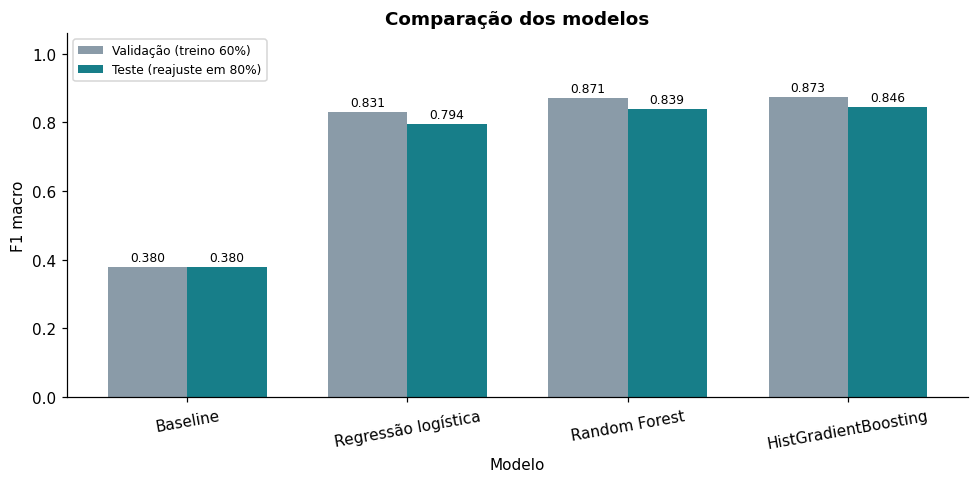

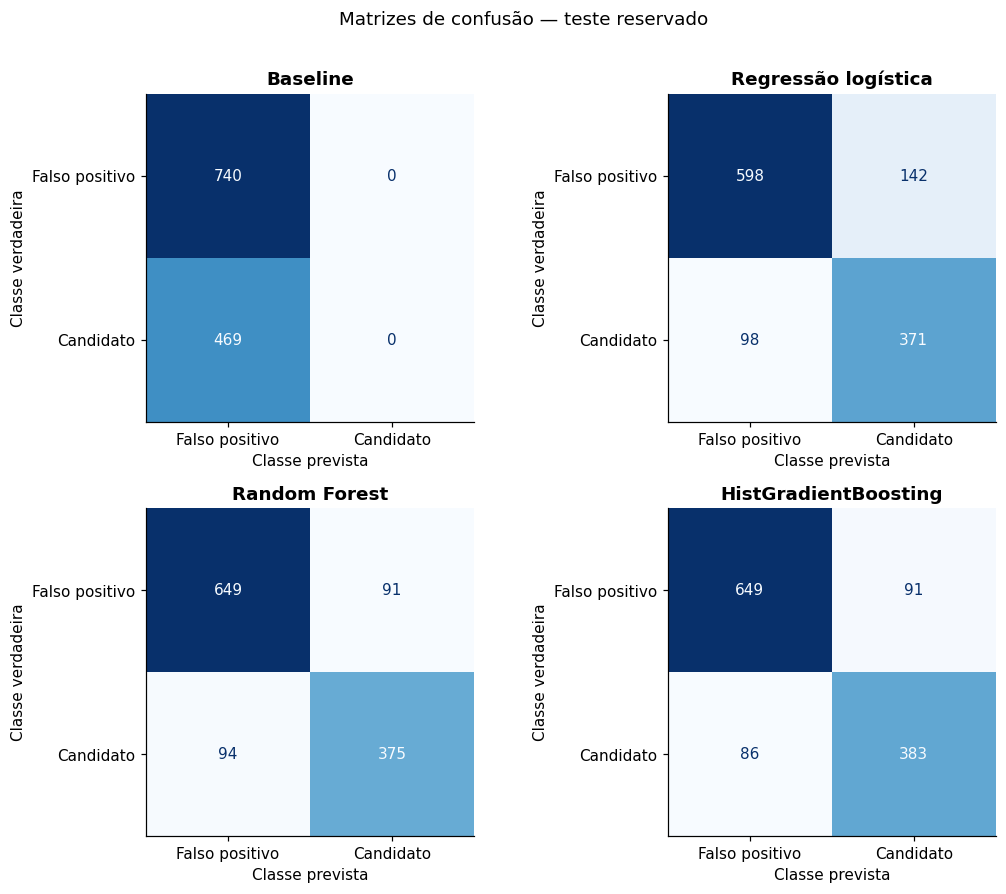

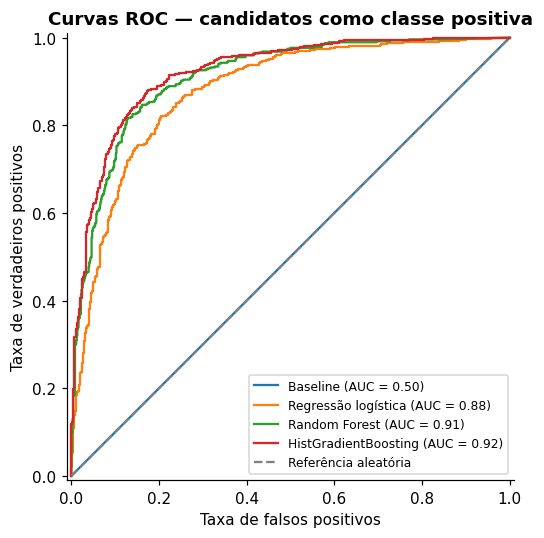

No teste, **383 candidatos** foram recuperados e **86 candidatos** foram descartados indevidamente. **91 falsos positivos do catálogo** foram classificados como candidatos; **649** foram corretamente rejeitados. Em uma triagem, perder candidatos reduz a sensibilidade, enquanto aceitar falsos alarmes aumenta o trabalho de acompanhamento.

In [11]:
ordem = ['Baseline'] + NOMES_MODELOS
valores_val = [baseline_val['F1 macro']] + [
    tabela_validacao.loc[nome, 'F1 macro validação'] for nome in NOMES_MODELOS]
posicoes = np.arange(len(ordem))
fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(posicoes - 0.18, valores_val, 0.36, label='Validação (treino 60%)', color='#8a9ba8')
b2 = ax.bar(posicoes + 0.18, tabela_teste.loc[ordem, 'F1 macro'], 0.36,
            label='Teste (reajuste em 80%)', color='#177e89')
ax.bar_label(b1, fmt='%.3f', padding=2, fontsize=8)
ax.bar_label(b2, fmt='%.3f', padding=2, fontsize=8)
ax.set_xticks(posicoes, ordem, rotation=10)
ax.set(xlabel='Modelo', ylabel='F1 macro', ylim=(0, 1.06), title='Comparação dos modelos')
ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()
fig.savefig(RESULTADOS / '04_comparacao_modelos.png', bbox_inches='tight')
plt.show()

fig, eixos = plt.subplots(2, 2, figsize=(10, 8))
for ax, nome in zip(eixos.flat, ordem):
    matriz = confusion_matrix(y_teste, predicoes_teste[nome], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=NOMES_CLASSES).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set(title=nome, xlabel='Classe prevista', ylabel='Classe verdadeira')
fig.suptitle('Matrizes de confusão — teste reservado', y=1.01)
fig.tight_layout()
fig.savefig(RESULTADOS / '05_matrizes_confusao.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for nome in ordem:
    RocCurveDisplay.from_predictions(y_teste, probabilidades_teste[nome],
                                    name=nome, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Referência aleatória')
ax.set(xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos',
       title='Curvas ROC — candidatos como classe positiva')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTADOS / '06_curvas_roc.png', bbox_inches='tight')
plt.show()

print('Relatório do modelo escolhido na validação:', modelo_escolhido)
print(classification_report(y_teste, predicoes_teste[modelo_escolhido],
                            labels=[0, 1], target_names=NOMES_CLASSES, digits=4,
                            zero_division=0))
tn, fp, fn, tp = confusion_matrix(y_teste, predicoes_teste[modelo_escolhido], labels=[0, 1]).ravel()
display(Markdown(
    f'No teste, **{tp} candidatos** foram recuperados e **{fn} candidatos** foram descartados '
    f'indevidamente. **{fp} falsos positivos do catálogo** foram classificados como candidatos; '
    f'**{tn}** foram corretamente rejeitados. Em uma triagem, perder candidatos reduz a '
    'sensibilidade, enquanto aceitar falsos alarmes aumenta o trabalho de acompanhamento.'))

## 11. Discussão e limites

As métricas descrevem a concordância com os rótulos DR25 nesta amostra. Os descritores e os rótulos vêm da mesma cadeia científica; resultados altos não são confirmação independente de planetas. Propriedades calculadas sob hipótese planetária também aparecem nos falsos positivos. O conjunto mistura origens distintas de falso positivo em uma única classe.

O filtro de uma estrela por exemplo reduz repetição de fonte, mas não elimina efeitos comuns da missão, do instrumento ou da seleção do catálogo. A exclusão de sistemas com múltiplos objetos e de linhas incompletas restringe a população estudada. Não estimamos taxas de ocorrência nem transferibilidade para TESS, outras missões ou curvas de luz brutas.

A comparação utiliza um único holdout. A busca repetida pode sobreajustar a validação; por isso mantivemos um teste separado. As diferenças de desempenho não recebem teste estatístico ou validação cruzada nesta versão. Não há análise causal ou ferramenta de importância de atributos: as relações da EDA são apenas descritivas.

In [12]:
resultado_escolhido = tabela_teste.loc[modelo_escolhido]
melhor_f1_teste = tabela_teste.loc[NOMES_MODELOS, 'F1 macro'].idxmax()
diferenca = resultado_escolhido['F1 macro'] - tabela_teste.loc['Baseline', 'F1 macro']
texto = (f'O algoritmo selecionado na validação foi **{modelo_escolhido}**, com F1 macro '
         f'**{tabela_validacao.loc[modelo_escolhido, "F1 macro validação"]:.4f}**. '
         f'Após reajuste em treino + validação, seu F1 macro no teste foi '
         f'**{resultado_escolhido["F1 macro"]:.4f}**, diferença de **{diferenca:.4f}** '
         'em relação ao baseline. ')
if melhor_f1_teste != modelo_escolhido:
    texto += (f'{melhor_f1_teste} obteve o maior F1 observado no teste, mas isso não '
              'muda a seleção feita previamente; escolher de novo pelo teste '
              'contaminaria a avaliação. ')
texto += ('As métricas de treino e validação acima ajudam a reconhecer maior ajuste '
          'ao treino, mas não isolam sua causa. Nenhum ajuste adicional foi feito com o teste.')
display(Markdown(texto))
f1_ajuste = tabela_validacao.loc[modelo_escolhido, 'F1 macro treino']
f1_validacao = tabela_validacao.loc[modelo_escolhido, 'F1 macro validação']
display(Markdown(
    f'O modelo escolhido apresentou F1 macro de **{f1_ajuste:.4f} no treino**, '
    f'**{f1_validacao:.4f} na validação** e **{resultado_escolhido["F1 macro"]:.4f} no teste**. '
    'A diferença entre ajuste e dados separados é um sinal de sobreajuste. '
    'A queda adicional da validação para o teste é compatível com reutilização '
    'da validação e variação amostral; esta divisão única não separa essas causas. '
    'Esse limite é relatado sem reotimizar usando o teste.'))

resumo_execucao = {'n_original': len(bruto), 'n_final': len(df), 'n_atributos': len(ATRIBUTOS),
    'classes': df[ALVO].value_counts().to_dict(), 'particoes': resumo_partes,
    'seed': SEED, 'trials_por_algoritmo': N_TRIALS,
    'modelo_escolhido_na_validacao': modelo_escolhido, 'tempo_buscas_s': tempo_total,
    'metricas_teste': metricas_teste, 'melhores_parametros': melhores_parametros,
    'matriz_modelo_escolhido': {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)},
    'versoes': versoes, 'origem': origem}
(RESULTADOS / 'resumo_execucao.json').write_text(
    json.dumps(resumo_execucao, ensure_ascii=False, indent=2), encoding='utf-8')
predicoes = df.loc[indices_teste, ['kepid', 'kepoi_name', ALVO]].copy()
for nome in ordem:
    predicoes[nome] = predicoes_teste[nome]
predicoes.to_csv(RESULTADOS / 'predicoes_teste.csv', index=False)
print('Históricos, parâmetros, gráficos e métricas salvos em:', RESULTADOS.name)

Históricos, parâmetros, gráficos e métricas salvos em: resultados


O algoritmo selecionado na validação foi **HistGradientBoosting**, com F1 macro **0.8734**. Após reajuste em treino + validação, seu F1 macro no teste foi **0.8462**, diferença de **0.4665** em relação ao baseline. As métricas de treino e validação acima ajudam a reconhecer maior ajuste ao treino, mas não isolam sua causa. Nenhum ajuste adicional foi feito com o teste.

O modelo escolhido apresentou F1 macro de **1.0000 no treino**, **0.8734 na validação** e **0.8462 no teste**. A diferença entre ajuste e dados separados é um sinal de sobreajuste. A queda adicional da validação para o teste é compatível com reutilização da validação e variação amostral; esta divisão única não separa essas causas. Esse limite é relatado sem reotimizar usando o teste.

## 12. Descrição do uso de IA neste trabalho

O ChatGPT/Codex foi utilizado para localizar e conferir a documentação, estruturar o estudo, escrever e revisar os textos e o código Python, organizar os arquivos e executar os experimentos. A ferramenta também auxiliou na conferência de vazamento de dados e na interpretação inicial das métricas. Os dados são observações do NASA Exoplanet Archive; não foram geradas amostras ou resultados fictícios. As métricas exibidas são provenientes da execução registrada neste notebook.

A autoria acadêmica exige que o estudante revise a fundamentação, confira os resultados e compreenda o código antes de submeter e apresentar o trabalho. Essa revisão pessoal não é presumida pela geração deste arquivo. Não se atribui à IA a descoberta ou confirmação de exoplanetas.

## 13. Referências

[1] NASA EXOPLANET ARCHIVE. *Data Columns in Kepler Objects of Interest Table*. https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html. DOI do arquivo/serviço: https://doi.org/10.26133/NEA4.

[2] NASA EXOPLANET ARCHIVE. *Purpose of Kepler Objects of Interest (KOI) Activity Tables*. https://exoplanetarchive.ipac.caltech.edu/docs/PurposeOfKOITable.html. Acesso por TAP: https://exoplanetarchive.ipac.caltech.edu/docs/TAP/usingTAP.html. Consulta e data de aquisição registradas em `dados/proveniencia.json`.

[3] THOMPSON, S. E. et al. *Planetary Candidates Observed by Kepler. VIII. A Fully Automated Catalog With Measured Completeness and Reliability Based on Data Release 25*. The Astrophysical Journal Supplement Series, 235, 38, 2018. https://doi.org/10.3847/1538-4365/aab4f9. Versão aberta: https://arxiv.org/abs/1710.06758.

[4] SCIKIT-LEARN. *train_test_split; model evaluation*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html; https://scikit-learn.org/stable/modules/model_evaluation.html.

[5] SCIKIT-LEARN. *LogisticRegression; StandardScaler; Pipeline*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html; https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html; https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html.

[6] SCIKIT-LEARN. *RandomForestClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.

[7] SCIKIT-LEARN. *HistGradientBoostingClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html.

[8] OPTUNA. *Study; TPESampler*. https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html; https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html.

[9] Material da disciplina. *Tiamat Instruções.pdf*. Ilum Escola de Ciência, 2026. Requisitos obrigatórios utilizados para definir o escopo.

Dados utilizados: NASA Exoplanet Archive, operado pelo California Institute of Technology sob contrato com a NASA, no Exoplanet Exploration Program. As referências web foram consultadas em 7 de novembro de 2026; consulte as versões de bibliotecas registradas na execução.

## 14. Conclusões e principais aprendizados

Este estudo comparou três algoritmos de classificação e um baseline em dados reais de candidatos a exoplanetas. O resultado quantitativo abaixo é calculado com a execução atual. A conclusão diz respeito à triagem do catálogo, e não à confirmação astronômica dos objetos.

In [13]:
display(Markdown(
    f'Foram analisados **{len(df):,} objetos** e **{len(ATRIBUTOS)} atributos**, com uma estrela '
    f'por exemplo. Cada um dos três algoritmos concluiu **{N_TRIALS} configurações distintas** '
    f'no Optuna. O escolhido na validação, **{modelo_escolhido}**, obteve no teste '
    f'**F1 macro = {resultado_escolhido["F1 macro"]:.4f}**, '
    f'**acurácia = {resultado_escolhido["Acurácia"]:.4f}** e '
    f'**recall de candidatos = {resultado_escolhido["Recall candidato"]:.4f}**. '
    f'O baseline apresentou **F1 macro = {tabela_teste.loc["Baseline", "F1 macro"]:.4f}**.\n\n'
    'Os principais aprendizados metodológicos são separar os dados antes de ajustar '
    'transformações, distinguir validação de teste, comparar com uma referência simples '
    'e avaliar as duas classes. A classificação automatizada pode apoiar a triagem, '
    'mas sua validade depende da população e dos rótulos utilizados. O estudo não '
    'determina quais variáveis causam a classe nem substitui observações de confirmação.'))

Foram analisados **6,041 objetos** e **25 atributos**, com uma estrela por exemplo. Cada um dos três algoritmos concluiu **100 configurações distintas** no Optuna. O escolhido na validação, **HistGradientBoosting**, obteve no teste **F1 macro = 0.8462**, **acurácia = 0.8536** e **recall de candidatos = 0.8166**. O baseline apresentou **F1 macro = 0.3797**.

Os principais aprendizados metodológicos são separar os dados antes de ajustar transformações, distinguir validação de teste, comparar com uma referência simples e avaliar as duas classes. A classificação automatizada pode apoiar a triagem, mas sua validade depende da população e dos rótulos utilizados. O estudo não determina quais variáveis causam a classe nem substitui observações de confirmação.